# Fine-tune YOLOv8m for face-expression classification

The first fine-tuning run reached **90.06% test accuracy** and **90.44% best validation accuracy**, below the previous YOLOv8m run (**90.56% test**, **90.75% best validation**). Training loss fell to 0.03 while validation loss rose after the best epoch, a clear overfitting signal.

This revised pass starts from the already trained YOLOv8m checkpoint when available, uses the original run's 256 px and milder augmentations, and a lower learning rate for cautious refinement. It may improve validation accuracy, but 95% is not guaranteed.

**Important:** this notebook has already evaluated the test set for the previous run. Use validation only to select another model. Any subsequent test score on this same split is exploratory, not an untouched final estimate; use a new independent test set for an unbiased final claim.

## 1. Environment and reproducibility

In [1]:
import os
import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import torch
import ultralytics
from ultralytics import YOLO
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
    print(f"GPU: {torch.cuda.get_device_name(0)} | CUDA {torch.version.cuda}")
else:
    print("No CUDA GPU found; CPU training will be slow.")
print("PyTorch:", torch.__version__, "| Ultralytics:", ultralytics.__version__)
print("Pandas:", pd.__version__)


GPU: NVIDIA GeForce RTX 5070 Ti | CUDA 12.8
PyTorch: 2.11.0+cu128 | Ultralytics: 8.4.165
Pandas: 3.0.3


Install the dependencies in the active kernel if imports above fail: `%pip install ultralytics scikit-learn pandas matplotlib pillow`. Restart the kernel after installing.

## 2. Dataset and training configuration

The default is the already-prepared, duplicate-aware 70/15/15 split. Set `FER_DATASET_DIR` or `FER_OUTPUT_DIR` before starting the kernel to override the paths. No source images are rewritten.

In [2]:
CLASS_NAMES = ["angry", "fear", "happy", "neutral", "sad", "surprise"]
SPLITS = ["train", "val", "test"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
BASELINE_TEST_ACCURACY = 0.9056
TARGET_ACCURACY = 0.95

workspace_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
default_dataset = next(
    (root / "outputs" / "_shared_work" / "dataset" for root in workspace_candidates
     if (root / "outputs" / "_shared_work" / "dataset").is_dir()),
    Path.cwd() / "outputs" / "_shared_work" / "dataset",
)
DATASET_DIR = Path(os.environ.get("FER_DATASET_DIR", str(default_dataset))).expanduser().resolve()
OUTPUT_DIR = Path(os.environ.get("FER_OUTPUT_DIR", str(Path.cwd() / "outputs" / "yolov8m_finetuned"))).expanduser().resolve()
PRETRAINED_WEIGHTS = "yolov8m-cls.pt"  # fallback if the prior YOLOv8m checkpoint is unavailable
BASELINE_CHECKPOINT = next(
    (root / "outputs" / "yolov8m" / "runs" / "yolov8m_70_15_15" / "weights" / "best.pt"
     for root in workspace_candidates
     if (root / "outputs" / "yolov8m" / "runs" / "yolov8m_70_15_15" / "weights" / "best.pt").is_file()),
    None,
)
INITIAL_WEIGHTS = str(BASELINE_CHECKPOINT) if BASELINE_CHECKPOINT else PRETRAINED_WEIGHTS

# Match the previous best run's resolution and batch; use a short, low-learning-rate refinement.
IMG_SIZE = 256
BATCH = 32
EPOCHS = 40
PATIENCE = 10
WORKERS = 0 if os.name == "nt" else min(8, os.cpu_count() or 2)
DEVICE = 0 if torch.cuda.is_available() else "cpu"

if not DATASET_DIR.is_dir():
    raise FileNotFoundError(f"Dataset folder not found: {DATASET_DIR}. Set FER_DATASET_DIR to its parent folder.")
for split in SPLITS:
    for class_name in CLASS_NAMES:
        folder = DATASET_DIR / split / class_name
        if not folder.is_dir():
            raise FileNotFoundError(f"Missing class folder: {folder}")
        count = sum(p.suffix.lower() in IMAGE_EXTENSIONS for p in folder.iterdir() if p.is_file())
        if count == 0:
            raise ValueError(f"No supported images found in {folder}")
print("Dataset:", DATASET_DIR)
print("Output:", OUTPUT_DIR)
print("Device:", DEVICE, "| Image size:", IMG_SIZE, "| Batch:", BATCH)
print("Initialization checkpoint:", INITIAL_WEIGHTS)
display(pd.DataFrame({split: {
    name: sum(p.suffix.lower() in IMAGE_EXTENSIONS for p in (DATASET_DIR / split / name).iterdir() if p.is_file())
    for name in CLASS_NAMES
} for split in SPLITS}))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


Dataset: D:\Shitol\last_codes\outputs\_shared_work\dataset
Output: D:\Shitol\last_codes\outputs\yolov8m_finetuned
Device: 0 | Image size: 256 | Batch: 32
Initialization checkpoint: D:\Shitol\last_codes\outputs\yolov8m\runs\yolov8m_70_15_15\weights\best.pt


,train,val,test
angry,2313,496,495
fear,1517,325,325
happy,3415,732,732
neutral,2908,623,623
sad,2764,592,593
surprise,2161,464,463


## 3. Fine-tune YOLOv8m-cls

This is a low-learning-rate continuation from the existing fine-tuned checkpoint (if found), not a fresh ImageNet-only run. It uses milder settings from the previous best YOLOv8m experiment and validation-based early stopping. Each run gets a unique directory so previous checkpoints are preserved.

In [3]:
run_name = time.strftime("yolov8m_256_refine_%Y%m%d_%H%M%S")
start_time = time.perf_counter()
model = YOLO(INITIAL_WEIGHTS)
train_result = model.train(
    data=str(DATASET_DIR),
    epochs=EPOCHS,
    patience=PATIENCE,
    imgsz=IMG_SIZE,
    batch=BATCH,
    device=DEVICE,
    workers=WORKERS,
    cache=False,
    amp=True,
    seed=SEED,
    deterministic=True,
    optimizer="AdamW",
    lr0=5e-5,
    lrf=0.10,
    cos_lr=True,
    warmup_epochs=3,
    weight_decay=0.05,
    dropout=0.30,
    scale=0.30,
    hsv_h=0.015,
    hsv_s=0.50,
    hsv_v=0.40,
    auto_augment="randaugment",
    erasing=0.10,
    fliplr=0.5,
    flipud=0.0,
    project=str(OUTPUT_DIR / "runs"),
    name=run_name,
    exist_ok=False,
    pretrained=True,
    plots=True,
    verbose=True,
)
BEST_PT = Path(model.trainer.best).resolve()
RUN_DIR = Path(model.trainer.save_dir).resolve()
if not BEST_PT.is_file():
    raise FileNotFoundError(f"Training ended but best checkpoint is missing: {BEST_PT}")
train_minutes = (time.perf_counter() - start_time) / 60
print(f"Training time: {train_minutes:.1f} minutes")
print("Best validation checkpoint:", BEST_PT)
print("Run directory:", RUN_DIR)


New https://pypi.org/project/ultralytics/8.4.208 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.165  Python-3.14.5 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16303MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=D:\Shitol\last_codes\outputs\_shared_work\dataset, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.3, dynamic=False, embed=None, epochs=40, erasing=0.1, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=256, iou=0.7, kobj=1.0, line_width=None, lr0=5e-05, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mod

If training stops with CUDA out-of-memory, reduce `BATCH` (e.g. 32 → 16 → 8), restart the training cell, and use the new run it creates. Do not delete the previous run. A lower `IMG_SIZE` is a further memory fallback.

## 4. Inspect learning curves and select inference policy on validation

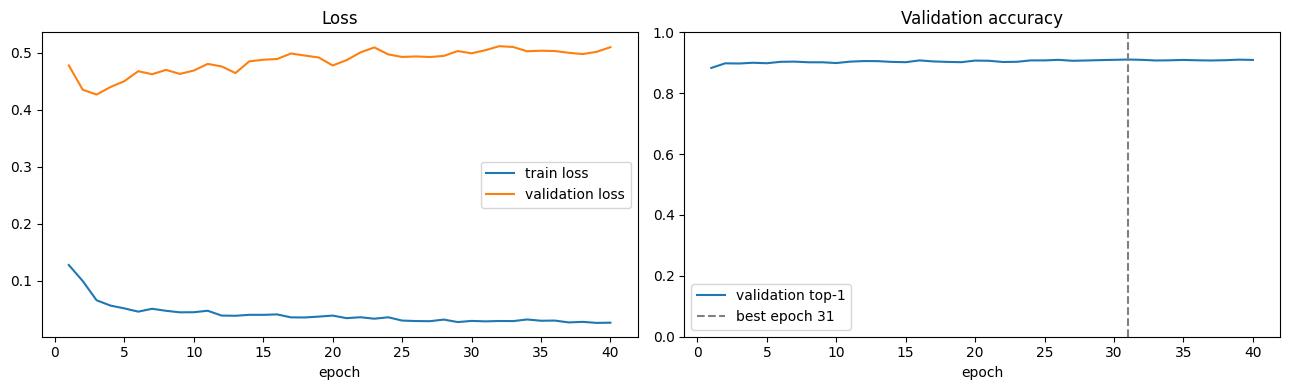

Best validation epoch: 31 | top-1: 0.9106


In [4]:
history_path = RUN_DIR / "results.csv"
if not history_path.is_file():
    raise FileNotFoundError(f"Ultralytics training history is missing: {history_path}")
history = pd.read_csv(history_path)
history.columns = history.columns.str.strip()
top1_col = "metrics/accuracy_top1"
if top1_col not in history:
    raise KeyError(f"Expected validation metric {top1_col!r}; found columns: {history.columns.tolist()}")
best_row = history.loc[history[top1_col].idxmax()]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for column, label in (("train/loss", "train loss"), ("val/loss", "validation loss")):
    if column in history:
        axes[0].plot(history["epoch"], history[column], label=label)
axes[0].set(title="Loss", xlabel="epoch")
axes[0].legend()
axes[1].plot(history["epoch"], history[top1_col], label="validation top-1")
axes[1].axvline(best_row["epoch"], color="gray", linestyle="--", label=f"best epoch {int(best_row['epoch'])}")
axes[1].set(title="Validation accuracy", xlabel="epoch", ylim=(0, 1))
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"Best validation epoch: {int(best_row['epoch'])} | top-1: {best_row[top1_col]:.4f}")


In [5]:
def image_paths(split):
    paths, labels = [], []
    for label, class_name in enumerate(CLASS_NAMES):
        files = sorted(p for p in (DATASET_DIR / split / class_name).iterdir()
                       if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
        paths.extend(files)
        labels.extend([label] * len(files))
    if not paths:
        raise ValueError(f"No images found in split {split!r}")
    return paths, np.asarray(labels, dtype=np.int64)


def predict_paths(classifier, paths, use_flip_tta=False, chunk_size=64):
    """Use Ultralytics' classification prediction transforms; optional TTA averages horizontal flips."""
    all_probs = []
    for start in range(0, len(paths), chunk_size):
        batch_paths = paths[start:start + chunk_size]
        images = []
        for path in batch_paths:
            with Image.open(path) as image:
                rgb = image.convert("RGB")
                images.append(rgb.copy())
                if use_flip_tta:
                    images.append(ImageOps.mirror(rgb))
        results = classifier.predict(
            source=images,
            imgsz=IMG_SIZE,
            device=DEVICE,
            batch=min(BATCH, len(images)),
            verbose=False,
        )
        batch_probs = np.stack([result.probs.data.cpu().numpy() for result in results])
        if use_flip_tta:
            batch_probs = (batch_probs[0::2] + batch_probs[1::2]) / 2.0
        all_probs.append(batch_probs)
    return np.concatenate(all_probs, axis=0)


best_model = YOLO(str(BEST_PT))
model_class_names = [best_model.names[i] for i in range(len(best_model.names))]
if model_class_names != CLASS_NAMES:
    raise ValueError(f"Model class order {model_class_names} differs from dataset {CLASS_NAMES}")
val_paths, y_val = image_paths("val")
val_probs_plain = predict_paths(best_model, val_paths, use_flip_tta=False)
val_acc_plain = accuracy_score(y_val, val_probs_plain.argmax(axis=1))
val_probs_flip = predict_paths(best_model, val_paths, use_flip_tta=True)
val_acc_flip = accuracy_score(y_val, val_probs_flip.argmax(axis=1))
USE_FLIP_TTA = bool(val_acc_flip > val_acc_plain)
print(f"Validation accuracy without TTA: {val_acc_plain:.4f}")
print(f"Validation accuracy with flip TTA: {val_acc_flip:.4f}")
print("Selected inference policy:", "horizontal-flip TTA" if USE_FLIP_TTA else "single view")
del val_probs_plain, val_probs_flip


Validation accuracy without TTA: 0.9106
Validation accuracy with flip TTA: 0.9097
Selected inference policy: single view


## 5. Final held-out test evaluation (run once after all choices)

The previous notebook run already read this test split. Run this cell only after selecting the refinement on validation, and treat its score as exploratory because the split has already been observed. If refining further, do not use this test score to choose settings; use a new independent test set for an unbiased final report.

              precision    recall  f1-score   support

       angry     0.9272    0.9010    0.9139       495
        fear     0.8495    0.8338    0.8416       325
       happy     0.9440    0.9440    0.9440       732
     neutral     0.8640    0.8973    0.8803       623
         sad     0.8814    0.9022    0.8917       593
    surprise     0.9303    0.8942    0.9119       463

    accuracy                         0.9025      3231
   macro avg     0.8994    0.8954    0.8972      3231
weighted avg     0.9030    0.9025    0.9026      3231

Test accuracy: 0.9025 | macro-F1: 0.8972
95% Wilson CI: [0.8918, 0.9123]
Previous YOLOv8m test accuracy: 0.9056
95% target achieved on this held-out split: False


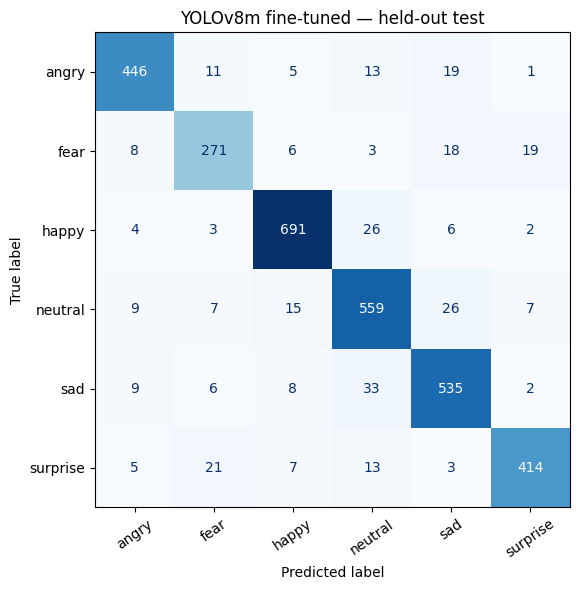

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay

test_paths, y_test = image_paths("test")
test_probs = predict_paths(best_model, test_paths, use_flip_tta=USE_FLIP_TTA)
y_pred = test_probs.argmax(axis=1)
test_accuracy = float(accuracy_score(y_test, y_pred))
test_macro_f1 = float(f1_score(y_test, y_pred, average="macro"))
test_report = classification_report(
    y_test, y_pred, labels=np.arange(len(CLASS_NAMES)), target_names=CLASS_NAMES,
    output_dict=True, zero_division=0,
)
test_cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(CLASS_NAMES)))

n = len(y_test)
z = 1.959963984540054
denom = 1 + z**2 / n
center = (test_accuracy + z**2 / (2 * n)) / denom
half_width = z * np.sqrt(test_accuracy * (1 - test_accuracy) / n + z**2 / (4 * n**2)) / denom
ci95 = [float(center - half_width), float(center + half_width)]
per_class_accuracy = {
    name: float(test_cm[i, i] / test_cm[i].sum()) if test_cm[i].sum() else 0.0
    for i, name in enumerate(CLASS_NAMES)
}

print(classification_report(y_test, y_pred, labels=np.arange(len(CLASS_NAMES)),
                            target_names=CLASS_NAMES, digits=4, zero_division=0))
print(f"Test accuracy: {test_accuracy:.4f} | macro-F1: {test_macro_f1:.4f}")
print(f"95% Wilson CI: [{ci95[0]:.4f}, {ci95[1]:.4f}]")
print(f"Previous YOLOv8m test accuracy: {BASELINE_TEST_ACCURACY:.4f}")
print("95% target achieved on this held-out split:", test_accuracy >= TARGET_ACCURACY)

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(test_cm, display_labels=CLASS_NAMES).plot(
    ax=ax, cmap="Blues", xticks_rotation=35, colorbar=False,
)
ax.set_title("YOLOv8m fine-tuned — held-out test")
plt.tight_layout()
plt.show()


In [7]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
prediction_frame = pd.DataFrame({
    "path": [str(path) for path in test_paths],
    "true_label": [CLASS_NAMES[i] for i in y_test],
    "predicted_label": [CLASS_NAMES[i] for i in y_pred],
    "confidence": test_probs.max(axis=1),
})
for i, class_name in enumerate(CLASS_NAMES):
    prediction_frame[f"prob_{class_name}"] = test_probs[:, i]
prediction_path = RUN_DIR / "test_predictions.csv"
confusion_path = RUN_DIR / "test_confusion_matrix.csv"
metrics_path = RUN_DIR / "metrics.json"
prediction_frame.to_csv(prediction_path, index=False)
pd.DataFrame(test_cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(confusion_path)
metrics = {
    "model": "yolov8m-cls",
    "checkpoint": str(BEST_PT),
    "dataset": str(DATASET_DIR),
    "img_size": IMG_SIZE,
    "flip_tta_selected_on_validation": USE_FLIP_TTA,
    "validation_accuracy_single_view": float(val_acc_plain),
    "validation_accuracy_flip_tta": float(val_acc_flip),
    "test_images": n,
    "test_accuracy": test_accuracy,
    "test_macro_f1": test_macro_f1,
    "test_accuracy_wilson_95_ci": ci95,
    "test_per_class_accuracy": per_class_accuracy,
    "baseline_test_accuracy": BASELINE_TEST_ACCURACY,
    "target_test_accuracy": TARGET_ACCURACY,
    "target_achieved": bool(test_accuracy >= TARGET_ACCURACY),
    "classification_report": test_report,
}
with metrics_path.open("w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=2)
print("Saved metrics:", metrics_path)
print("Saved predictions:", prediction_path)
print("Saved confusion matrix:", confusion_path)
print("Checkpoint:", BEST_PT)


Saved metrics: D:\Shitol\last_codes\outputs\yolov8m_finetuned\runs\yolov8m_256_refine_20261110_021209\metrics.json
Saved predictions: D:\Shitol\last_codes\outputs\yolov8m_finetuned\runs\yolov8m_256_refine_20261110_021209\test_predictions.csv
Saved confusion matrix: D:\Shitol\last_codes\outputs\yolov8m_finetuned\runs\yolov8m_256_refine_20261110_021209\test_confusion_matrix.csv
Checkpoint: D:\Shitol\last_codes\outputs\yolov8m_finetuned\runs\yolov8m_256_refine_20261110_021209\weights\best.pt


## Outputs and next steps

- Best validation-selected weights: `outputs/yolov8m_finetuned/runs/<run>/weights/best.pt`
- Final metrics: `outputs/yolov8m_finetuned/runs/<run>/metrics.json`
- Per-image final predictions: `outputs/yolov8m_finetuned/runs/<run>/test_predictions.csv`
- Confusion matrix counts: `outputs/yolov8m_finetuned/runs/<run>/test_confusion_matrix.csv`

If test accuracy is below 95%, do not change settings based on test errors and report the same test split repeatedly as if it were independent. Inspect validation errors, verify ambiguous labels and duplicates, consider collecting more representative data, and tune only against validation. A higher training score alone is not evidence of better generalization.